In [ ]:
from google.colab import drive
import os
import shutil

# 1. Google Drive'ı Bağla
drive.mount('/content/drive')

# 2. Drive'dan yedeklenen dosyaları yerel disk alanına kopyala
print("Yedek dosyaları Google Drive'dan indiriliyor...")
shutil.copy('/content/drive/My Drive/opencv_cuda/cv2_cuda_backup.zip', '/content/')
shutil.copy('/content/drive/My Drive/opencv_cuda/opencv_libs_backup.zip', '/content/')

# 3. Python paket klasörünü oluştur ve dosyaları çıkart
print("Python cv2 paketi kuruluyor...")
os.makedirs('/usr/local/lib/python3.13/dist-packages/cv2', exist_ok=True)
!unzip -q -o /content/cv2_cuda_backup.zip -d /usr/local/lib/python3.13/dist-packages/cv2

# 4. Paylaşılan C++ kütüphanelerini çıkart
print("Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...")
!unzip -q -o /content/opencv_libs_backup.zip -d /usr/local/lib

# 5. Sistem dinamik kütüphane bağlayıcısını güncelle
print("Kütüphane yolları sistemde güncelleniyor...")
!ldconfig

# 6. Test Et
print("\n=== KURULUM TAMAMLANDI ===")
import cv2
cuda_devices = cv2.cuda.getCudaEnabledDeviceCount()
print(f"CUDA Destekli Cihaz Sayısı: {cuda_devices}")
if cuda_devices > 0:
    print("Tebrikler! OpenCV CUDA desteğiyle başarıyla geri yüklendi.")
    cv2.cuda.printCudaDeviceInfo(0)
else:
    print("Uyarı: Kurulum tamamlandı ancak GPU etkinleştirilmemiş olabilir. Runtime ayarlarından GPU seçtiğinize emin olun.")

Mounted at /content/drive
Yedek dosyaları Google Drive'dan indiriliyor...
Python cv2 paketi kuruluyor...
Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...
Kütüphane yolları sistemde güncelleniyor...
/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libjulia.so.1.12 is not a sym

### SGBM (Semi-Global Block Matching) Algoritmasında Smoothness (Yumuşak Geçiş) Parametreleri

SGBM algoritmasında enerji fonksiyonunu minimize ederken iki temel yumuşak geçiş (smoothness) cezalandırma parametresi kullanılır: **$P_1$** ve **$P_2$**.

$$\text{Enerji} = \sum_{p} C(p, D_p) + \sum_{q \in N_p} P_1 \cdot I(|D_p - D_q| = 1) + \sum_{q \in N_p} P_2 \cdot I(|D_p - D_q| > 1)$$

1. **$P_1$ (Küçük Değişim Cezası):**
   - Komşu pikseller arasındaki disparite farkının tam olarak **1 piksel** olduğu durumlarda uygulanan cezadır.
   - Eğik, yumuşak eğimli veya kavisli yüzeylerde (örneğin küre veya rampa yüzeyi) disparitenin kademeli olarak değişmesine izin vermek için bu parametre nispeten **küçük** tutulur.

2. **$P_2$ (Büyük Değişim Cezası):**
   - Komşu pikseller arasındaki disparite farkının **1 pikselden daha büyük** olduğu durumlarda uygulanan cezadır.
   - Derinliğin ani ve keskin bir şekilde değiştiği cisim kenarlarını/sınırlarını korumak için kullanılır. Bu yüzden $P_2 > P_1$ olacak şekilde tanımlanır.
   - Bu parametre, pikseller arasındaki geçişin rastgele sıçramalar yapmasını engeller ve gürültüyü baskılar. Görüntüdeki gerçek nesne sınırlarında ($P_2$ cezası ödenerek) keskin derinlik değişimleri elde edilir.

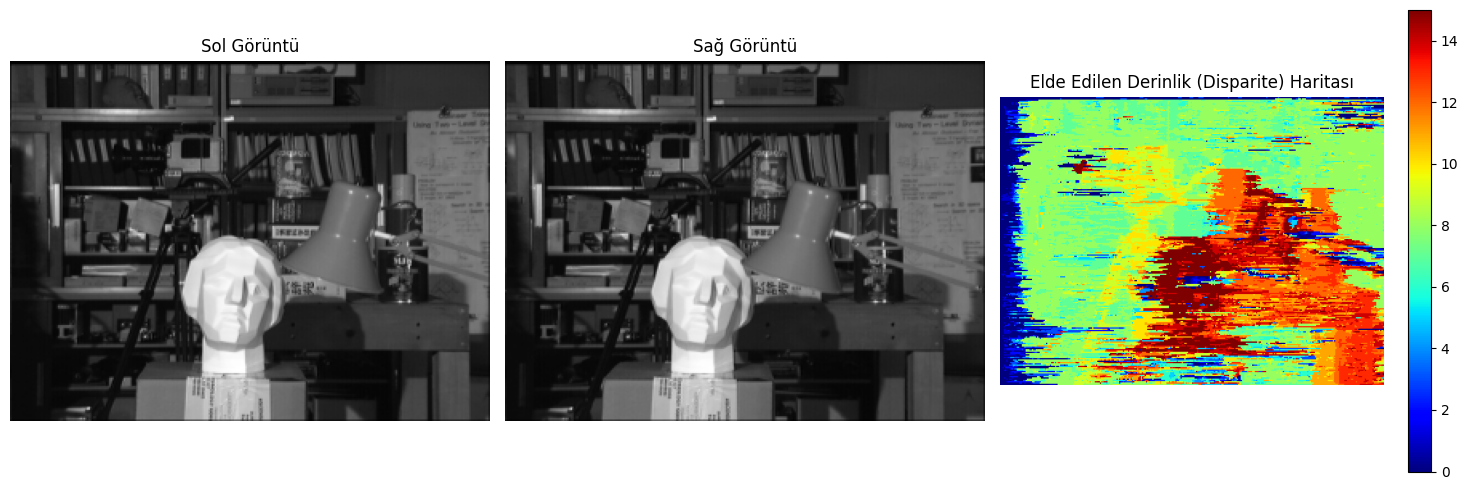

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def compute_census_transform(img):
    """Census dönüşümü ile piksellerin yerel doku bilgisini çıkarır."""
    h, w = img.shape
    census = np.zeros((h, w), dtype=np.uint64)

    # 3x3 pencere için hızlı kaydırma yöntemiyle census hesabı
    for i in range(-1, 2):
        for j in range(-1, 2):
            if i == 0 and j == 0:
                continue
            shift = (i + 1) * 3 + (j + 1)
            shifted = np.roll(np.roll(img, -i, axis=0), -j, axis=1)
            census |= ((img > shifted).astype(np.uint64) << shift)
    return census

def compute_matching_cost(census_left, census_right, num_disp):
    """Census farklarının Hamming mesafesiyle ilk eşleme maliyetini (Cost Volume) hesaplar."""
    h, w = census_left.shape
    cost_volume = np.zeros((h, w, num_disp), dtype=np.uint8)

    for d in range(num_disp):
        # Sağ resmi d kadar sağa kaydırıp karşılaştırıyoruz
        shifted_right = np.zeros_like(census_right)
        if d > 0:
            shifted_right[:, d:] = census_right[:, :-d]
        else:
            shifted_right = census_right

        # Hamming mesafesi (XOR ve bit sayma)
        xor_res = census_left ^ shifted_right
        # Bit sayılarını hesaplama
        cost_volume[:, :, d] = np.vectorize(lambda x: bin(int(x)).count('1'))(xor_res)

        # Geçersiz eşleşme alanlarını sınırlandırma
        if d > 0:
            cost_volume[:, :d, d] = 255

    return cost_volume

def aggregate_costs_horizontal(cost_volume, P1, P2):
    """Yumuşak geçiş cezalarını uygulayarak tek bir doğrultuda (Soldan Sağa) dinamik programlama maliyeti."""
    h, w, num_disp = cost_volume.shape
    L = np.zeros_like(cost_volume, dtype=np.float32)
    L[:, 0, :] = cost_volume[:, 0, :]

    for x in range(1, w):
        for d in range(num_disp):
            # Bir önceki pikselin d disparitesindeki maliyeti
            c_same = L[:, x-1, d]

            # d-1 ve d+1 durumundaki maliyetler (P1 cezası)
            c_p1_minus = L[:, x-1, max(0, d-1)] + P1
            c_p1_plus = L[:, x-1, min(num_disp-1, d+1)] + P1

            # Herhangi bir disparite değişikliği (P2 cezası)
            c_p2 = np.min(L[:, x-1, :], axis=1) + P2

            # Minimum yolu bulma ve normalizasyon
            min_prev = np.minimum(np.minimum(c_same, c_p1_minus), np.minimum(c_p1_plus, c_p2))
            L[:, x, d] = cost_volume[:, x, d] + min_prev - np.min(L[:, x-1, :], axis=1)

    return L

# 1. Görüntüleri Yükleme ve Ön İşleme
img_left = cv2.imread('/content/görsel.png', cv2.IMREAD_GRAYSCALE)
img_right = cv2.imread('/content/görsel1.png', cv2.IMREAD_GRAYSCALE)

# Performans ve bellek yönetimi için çözünürlüğü makul bir seviyeye getirelim
target_width = 300
aspect_ratio = img_left.shape[0] / img_left.shape[1]
target_height = int(target_width * aspect_ratio)

img_left_resized = cv2.resize(img_left, (target_width, target_height))
img_right_resized = cv2.resize(img_right, (target_width, target_height))

# 2. Census Dönüşümü
census_l = compute_census_transform(img_left_resized)
census_r = compute_census_transform(img_right_resized)

# 3. Parametreler ve İlk Maliyet Matrisi
max_disparity = 16
P1 = 3
P2 = 15

cost_vol = compute_matching_cost(census_l, census_r, max_disparity)

# 4. Maliyet Birleştirme (Yumuşaklık kısıtları ile soldan sağa yönlü süzgeç)
aggregated_cost = aggregate_costs_horizontal(cost_vol, P1, P2)

# 5. En Küçük Maliyetli Dispariteyi Seçme (Winner-Take-All)
disparity_map = np.argmin(aggregated_cost, axis=2)

# Görselleştirme
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title("Sol Görüntü")
plt.imshow(img_left_resized, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("Sağ Görüntü")
plt.imshow(img_right_resized, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Elde Edilen Derinlik (Disparite) Haritası")
plt.imshow(disparity_map, cmap='jet')
plt.colorbar()
plt.axis('off')

plt.tight_layout()
plt.show()